In [1]:
%pip install ultralytics opencv-python matplotlib pillow


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /Users/aradmishkal/.local/pipx/venvs/jupyterlab/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from ultralytics import YOLO

model = YOLO("weights.pt")

print("Model loaded successfully!")
print("Classes:", model.names)

Model loaded successfully!
Classes: {0: 'ball', 1: 'player_1', 2: 'player_2', 3: 'player_3', 4: 'player_4', 5: 'player_5'}


In [3]:

import cv2
import csv
from pathlib import Path
from ultralytics import YOLO
from tqdm.auto import tqdm
import math

# ==========================================
# 1. SETTINGS
# ==========================================

model = YOLO("weights.pt")

video_path = "test_2.mp4"
output_path = "tracked_basketball.mp4"
csv_path = "player_positions.csv"

CONFIDENCE = 0.25
JUMP_THRESHOLD = 10.0  # Maximum allowed movement in pixels per frame

CLASS_IDS = {
    "ball": 0,
    "player_1": 1,
    "player_2": 2,
    "player_3": 3,
    "player_4": 4,
    "player_5": 5,
}

# Remember the last accepted position of each class
last_positions = {}

print("Model loaded successfully!")
print("Classes:", model.names)
print("Jump threshold:", JUMP_THRESHOLD, "pixels/frame")

# ==========================================
# 2. OPEN VIDEO
# ==========================================

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

if fps <= 0:
    raise ValueError("Invalid video FPS.")

# ==========================================
# 3. OUTPUT VIDEO
# ==========================================

writer_video = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer_video.isOpened():
    raise RuntimeError(f"Cannot create output video: {output_path}")

# ==========================================
# 4. TRACK AND SAVE
# ==========================================

try:
    with open(csv_path, "w", newline="") as file:
        writer_csv = csv.writer(file)

        writer_csv.writerow([
            "frame",
            "time_seconds",
            "class",
            "track_id",
            "x",
            "y",
            "confidence"
        ])

        results = model.track(
            source=video_path,
            stream=True,
            persist=True,
            tracker="botsort.yaml",
            conf=CONFIDENCE,
            verbose=False
        )

        for frame_number, result in enumerate(
            tqdm(results, total=total_frames, desc="Processing video")
        ):
            frame = result.orig_img.copy()
            boxes = result.boxes

            if boxes is not None and len(boxes) > 0:
                xywh = boxes.xywh.cpu().numpy()
                classes = boxes.cls.cpu().numpy().astype(int)
                confidences = boxes.conf.cpu().numpy()

                for box, class_id, confidence in zip(
                    xywh, classes, confidences
                ):
                    class_name = model.names[class_id]

                    # Only use trained classes
                    if class_name not in CLASS_IDS:
                        continue

                    track_id = CLASS_IDS[class_name]

                    x, y, box_w, box_h = map(float, box)

                    # ----------------------------------
                    # JUMP FILTER
                    # ----------------------------------

                    previous = last_positions.get(class_name)

                    if previous is not None:
                        prev_x, prev_y, prev_frame = previous

                        frame_gap = frame_number - prev_frame

                        # Scale threshold by elapsed frames
                        allowed_distance = JUMP_THRESHOLD * frame_gap

                        distance = math.hypot(
                            x - prev_x,
                            y - prev_y
                        )

                        if distance > allowed_distance:
                            # Reject suspicious detection
                            continue

                    # Accept and remember position
                    last_positions[class_name] = (
                        x, y, frame_number
                    )

                    # ----------------------------------
                    # DRAW BOX AND LABEL
                    # ----------------------------------

                    x1 = int(x - box_w / 2)
                    y1 = int(y - box_h / 2)
                    x2 = int(x + box_w / 2)
                    y2 = int(y + box_h / 2)

                    color = (
                        (0, 0, 255)
                        if class_name == "ball"
                        else (0, 255, 0)
                    )

                    cv2.rectangle(
                        frame, (x1, y1), (x2, y2), color, 2
                    )

                    label = f"{class_name} ID:{track_id}"

                    cv2.putText(
                        frame,
                        label,
                        (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        color,
                        2,
                        cv2.LINE_AA
                    )

                    # ----------------------------------
                    # SAVE ACCEPTED DETECTION TO CSV
                    # ----------------------------------

                    writer_csv.writerow([
                        frame_number,
                        round(frame_number / fps, 3),
                        class_name,
                        track_id,
                        round(x, 2),
                        round(y, 2),
                        round(float(confidence), 3)
                    ])

            # Write every frame
            writer_video.write(frame)

finally:
    writer_video.release()

print("\nProcessing finished!")
print(f"Output video: {Path(output_path).resolve()}")
print(f"Output CSV:   {Path(csv_path).resolve()}")


Model loaded successfully!
Classes: {0: 'ball', 1: 'player_1', 2: 'player_2', 3: 'player_3', 4: 'player_4', 5: 'player_5'}
Jump threshold: 10.0 pixels/frame


Processing video:   0%|          | 0/1120 [00:00<?, ?it/s]


Processing finished!
Output video: /Users/aradmishkal/jupyter_files/Final_Project_Computer_Vision/tracked_basketball.mp4
Output CSV:   /Users/aradmishkal/jupyter_files/Final_Project_Computer_Vision/player_positions.csv


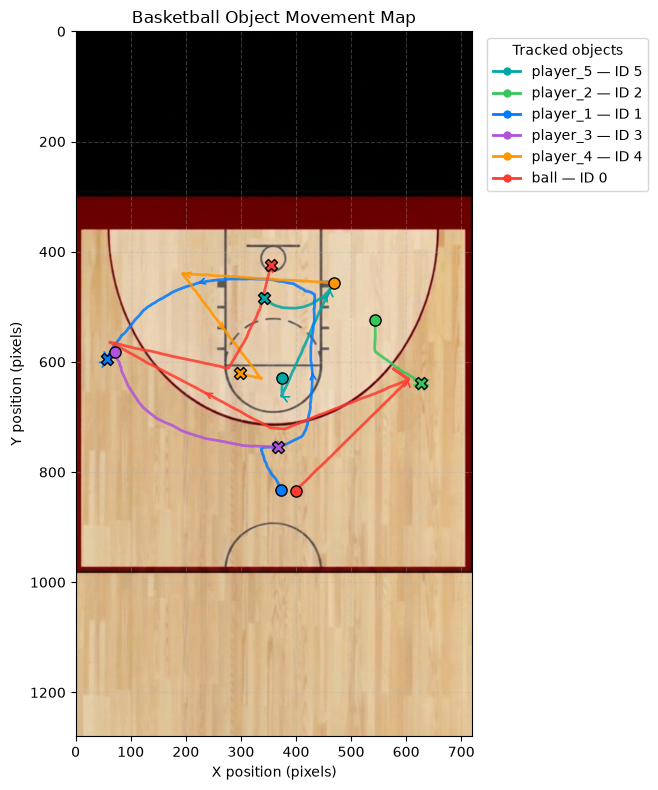

Video dimensions: 720 × 1280
Background dimensions: 720 × 1280
Total detections plotted: 6335
Movement map displayed successfully.


In [6]:

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# ==========================================
# 1. LOAD CSV, VIDEO DIMENSIONS, AND BACKGROUND
# ==========================================

df = pd.read_csv("player_positions.csv")

cap = cv2.VideoCapture("test_2.mp4")
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

if video_width <= 0 or video_height <= 0:
    raise ValueError("Could not read video dimensions.")

# Load background image
background = cv2.imread("background.jpeg")

if background is None:
    raise FileNotFoundError("Could not find background.jpeg")

# Resize background to match video dimensions exactly
background = cv2.resize(
    background,
    (video_width, video_height),
    interpolation=cv2.INTER_AREA
)

# Convert BGR to RGB for matplotlib
background = cv2.cvtColor(background, cv2.COLOR_BGR2RGB)

# Clean data
df = df.dropna(subset=["class", "track_id", "x", "y", "frame"])
df["track_id"] = df["track_id"].astype(int)

# Keep only the six trained classes
allowed_classes = [
    "ball", "player_1", "player_2",
    "player_3", "player_4", "player_5"
]
df = df[df["class"].isin(allowed_classes)]

# ==========================================
# 2. CREATE MOVEMENT MAP
# ==========================================

fig, ax = plt.subplots(figsize=(14, 8))

# Display background image behind movement paths
ax.imshow(
    background,
    extent=[0, video_width, video_height, 0],
    aspect="auto",
    zorder=0
)

colors = {
    "ball": "#ff3b30",
    "player_1": "#007aff",
    "player_2": "#34c759",
    "player_3": "#af52de",
    "player_4": "#ff9500",
    "player_5": "#00a6a6"
}

legend_handles = []

for (class_name, track_id), group in df.groupby(
    ["class", "track_id"], sort=False
):
    group = group.sort_values("frame")

    x = group["x"].to_numpy()
    y = group["y"].to_numpy()
    color = colors[class_name]

    # Movement path
    ax.plot(
        x, y,
        color=color,
        linewidth=2,
        alpha=0.85,
        zorder=2
    )

    # Starting position
    ax.scatter(
        x[0], y[0],
        color=color,
        marker="o",
        s=65,
        edgecolors="black",
        zorder=5
    )

    # Final position
    ax.scatter(
        x[-1], y[-1],
        color=color,
        marker="X",
        s=75,
        edgecolors="black",
        zorder=5
    )

    # Direction arrows
    if len(x) >= 8:
        indices = np.linspace(
            1, len(x) - 2,
            min(5, len(x) - 2),
            dtype=int
        )

        for j in indices:
            ax.annotate(
                "",
                xy=(x[j + 1], y[j + 1]),
                xytext=(x[j], y[j]),
                arrowprops=dict(
                    arrowstyle="->",
                    color=color,
                    lw=1.2
                ),
                zorder=3
            )

    legend_handles.append(
        Line2D(
            [0], [0],
            color=color,
            lw=2,
            marker="o",
            markersize=5,
            label=f"{class_name} — ID {track_id}"
        )
    )

# ==========================================
# 3. FORMAT AND DISPLAY
# ==========================================

ax.set_xlim(0, video_width)
ax.set_ylim(video_height, 0)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("X position (pixels)")
ax.set_ylabel("Y position (pixels)")
ax.set_title("Basketball Object Movement Map")

ax.grid(True, linestyle="--", alpha=0.3)

if legend_handles:
    ax.legend(
        handles=legend_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        title="Tracked objects"
    )

plt.tight_layout()
plt.show()

print(f"Video dimensions: {video_width} × {video_height}")
print(f"Background dimensions: {background.shape[1]} × {background.shape[0]}")
print(f"Total detections plotted: {len(df)}")
print("Movement map displayed successfully.")


**IGNORE THIS - I WAS CHECKING SOMETINHG WITH THE THRESHOLD**

TOP 10 BIGGEST JUMPS — PLAYER 2
 frame  next_frame      x      y  next_x  next_y     dx    dy  distance
   900       901.0 141.32 581.61  627.02  637.72 485.70 56.11    488.93
   901       902.0 143.46 582.16  627.01  637.73 483.55 55.57    486.73
   902       903.0 149.20 583.55  627.02  637.72 477.82 54.17    480.88
   905       906.0 159.19 586.17  627.01  637.73 467.82 51.56    470.65
   906       907.0 164.50 587.12  627.02  637.73 462.52 50.61    465.28
   907       908.0 167.16 587.71  627.01  637.73 459.85 50.02    462.56
   796       797.0 178.65 626.03  627.04  637.73 448.39 11.70    448.54
   911       912.0 183.00 591.43  627.01  637.73 444.01 46.30    446.42
   795       796.0 180.77 627.15  627.04  637.73 446.27 10.58    446.40
   912       913.0 189.85 592.87  627.02  637.73 437.17 44.86    439.47


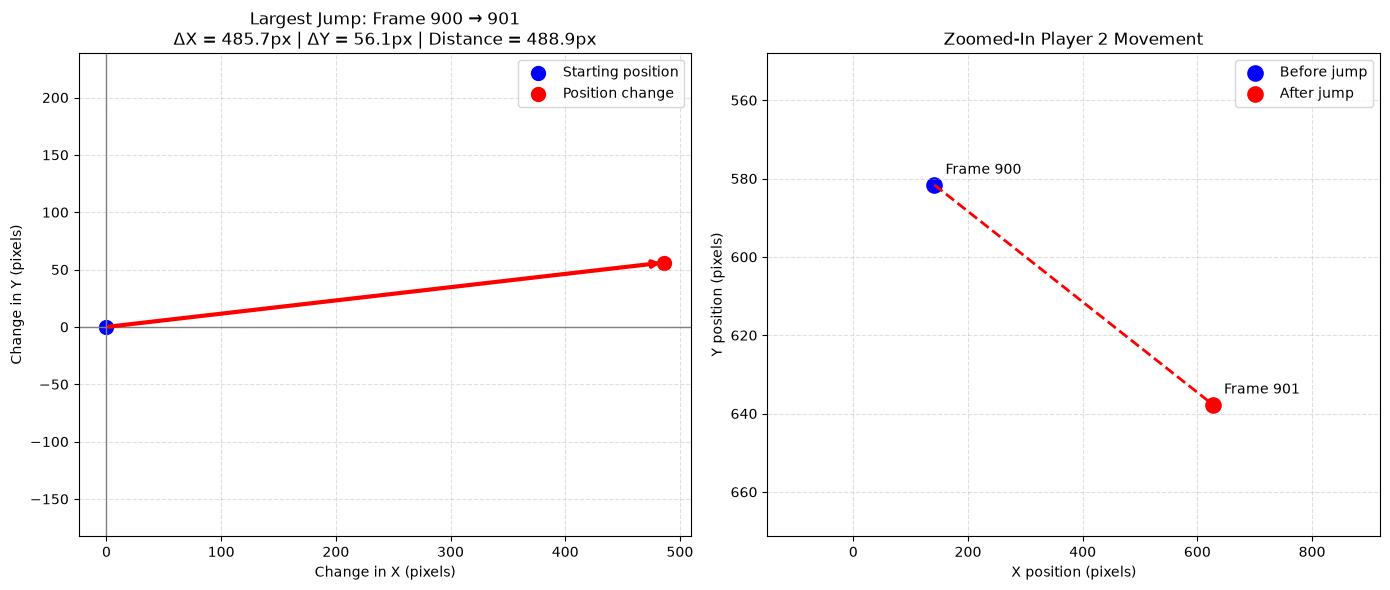

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD PLAYER 2 DATA
# ==========================================

df = pd.read_csv("player_positions.csv")

player = df[df["class"] == "player_2"].copy()
player = player.dropna(subset=["frame", "x", "y"])
player = player.sort_values("frame").reset_index(drop=True)

if len(player) < 2:
    raise ValueError("Not enough detections for player_2.")

# ==========================================
# 2. CALCULATE POSITION JUMPS
# ==========================================

player["next_frame"] = player["frame"].shift(-1)
player["next_x"] = player["x"].shift(-1)
player["next_y"] = player["y"].shift(-1)

player["frame_gap"] = player["next_frame"] - player["frame"]
player["dx"] = player["next_x"] - player["x"]
player["dy"] = player["next_y"] - player["y"]

player["distance"] = np.sqrt(
    player["dx"]**2 + player["dy"]**2
)

# Compare consecutive detections only (no missing frames)
jumps = player[player["frame_gap"] == 1].dropna(
    subset=["distance"]
).copy()

if jumps.empty:
    raise ValueError("No consecutive-frame detections found for player_2.")

# Largest jumps first
jumps = jumps.sort_values("distance", ascending=False)

print("TOP 10 BIGGEST JUMPS — PLAYER 2")
print(
    jumps[[
        "frame", "next_frame", "x", "y",
        "next_x", "next_y", "dx", "dy", "distance"
    ]].head(10).round(2).to_string(index=False)
)

# ==========================================
# 3. PLOT THE BIGGEST JUMP
# ==========================================

biggest = jumps.iloc[0]

x1, y1 = biggest["x"], biggest["y"]
x2, y2 = biggest["next_x"], biggest["next_y"]
distance = biggest["distance"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: X and Y displacement
ax = axes[0]
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)

ax.annotate(
    "",
    xy=(biggest["dx"], biggest["dy"]),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle="->", color="red", lw=3)
)

ax.scatter(0, 0, color="blue", s=100, label="Starting position")
ax.scatter(
    biggest["dx"], biggest["dy"],
    color="red", s=100, label="Position change"
)

ax.set_xlabel("Change in X (pixels)")
ax.set_ylabel("Change in Y (pixels)")
ax.set_title(
    f"Largest Jump: Frame {int(biggest['frame'])} → "
    f"{int(biggest['next_frame'])}\n"
    f"ΔX = {biggest['dx']:.1f}px | "
    f"ΔY = {biggest['dy']:.1f}px | "
    f"Distance = {distance:.1f}px"
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
ax.set_aspect("equal", adjustable="datalim")

# Right: Actual positions in video coordinates
ax = axes[1]

ax.plot(
    [x1, x2], [y1, y2],
    color="red", linewidth=2, linestyle="--"
)
ax.scatter(x1, y1, color="blue", s=120, label="Before jump")
ax.scatter(x2, y2, color="red", s=120, label="After jump")

ax.annotate(
    f"Frame {int(biggest['frame'])}",
    (x1, y1), xytext=(8, 8), textcoords="offset points"
)
ax.annotate(
    f"Frame {int(biggest['next_frame'])}",
    (x2, y2), xytext=(8, 8), textcoords="offset points"
)

# Zoom around the jump
pad_x = max(abs(x2 - x1) * 0.6, 30)
pad_y = max(abs(y2 - y1) * 0.6, 30)

ax.set_xlim(min(x1, x2) - pad_x, max(x1, x2) + pad_x)
ax.set_ylim(max(y1, y2) + pad_y, min(y1, y2) - pad_y)

ax.set_xlabel("X position (pixels)")
ax.set_ylabel("Y position (pixels)")
ax.set_title("Zoomed-In Player 2 Movement")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()


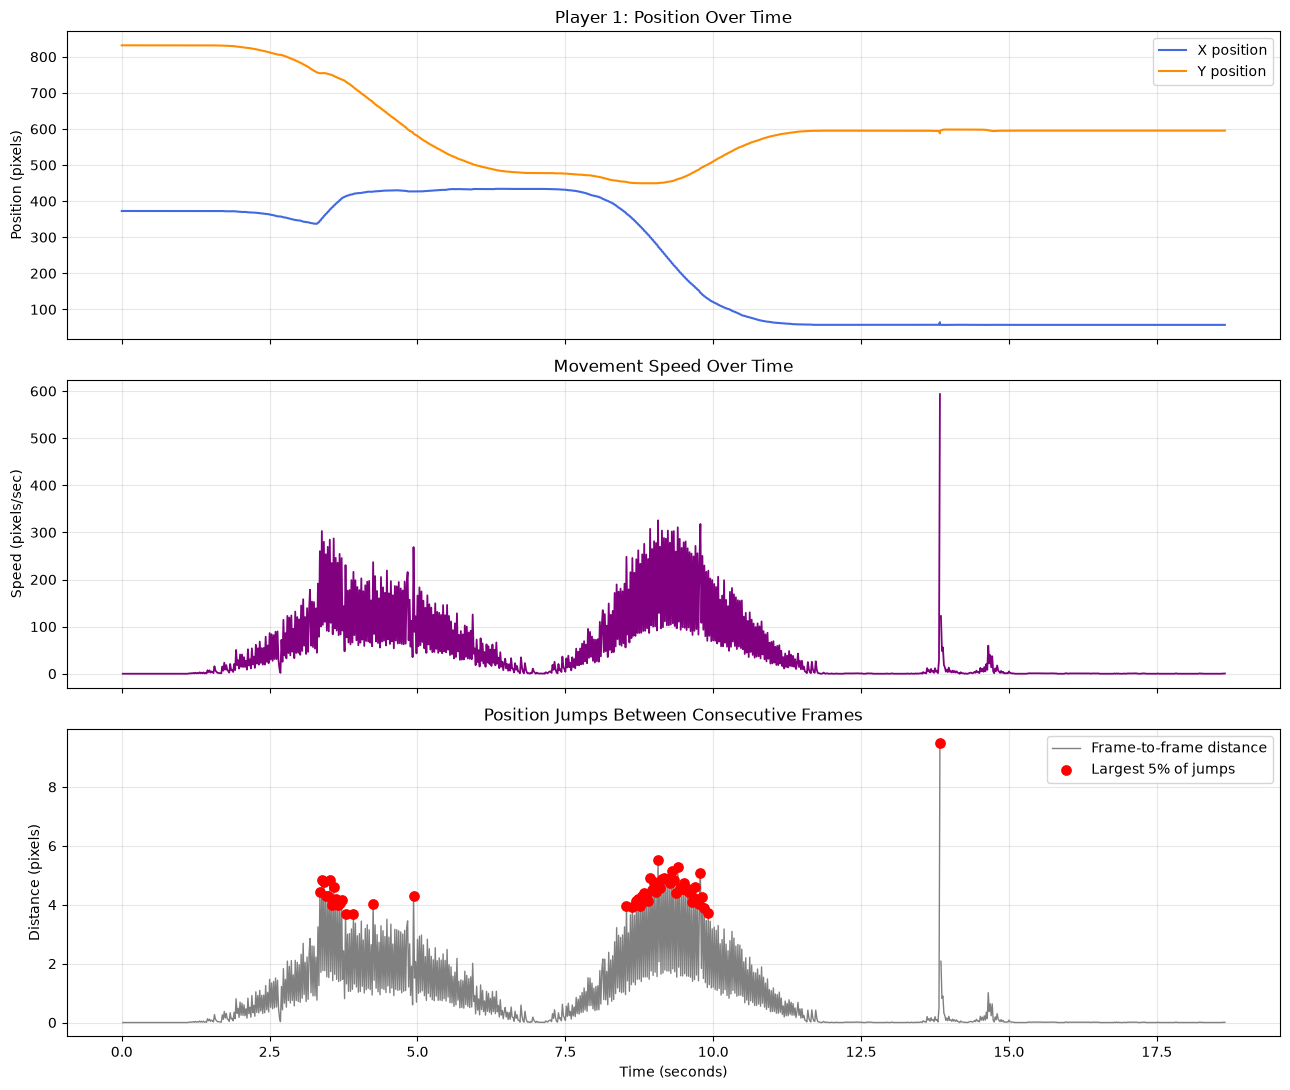

PLAYER 1 MOVEMENT SUMMARY
-------------------------
Detections: 1121
Average speed: 48.07 pixels/sec
Maximum speed: 593.53 pixels/sec
Largest consecutive-frame jump: 9.50 pixels
Large jumps detected: 56
Note: Speed is measured in image pixels, not meters per second.


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD PLAYER 1 DATA
# ==========================================

df = pd.read_csv("player_positions.csv")

player = df[df["class"] == "player_1"].copy()
player = player.dropna(
    subset=["frame", "time_seconds", "x", "y"]
)
player = player.sort_values("frame").reset_index(drop=True)

if len(player) < 2:
    raise ValueError("Not enough detections for player_1.")

# ==========================================
# 2. CALCULATE MOVEMENT
# ==========================================

player["dt"] = player["time_seconds"].diff()
player["dx"] = player["x"].diff()
player["dy"] = player["y"].diff()

# Euclidean distance between detections
player["distance"] = np.sqrt(
    player["dx"]**2 + player["dy"]**2
)

# Speed in pixels per second
player["speed"] = (
    player["distance"] / player["dt"].where(player["dt"] > 0)
)

# Frame gap: detect missing frames
player["frame_gap"] = player["frame"].diff()

# Exclude movements spanning missing frames from
# the consecutive-frame speed/jump analysis
consecutive = player["frame_gap"] == 1
player.loc[~consecutive, ["speed", "distance"]] = np.nan

# Flag unusually large jumps using the 95th percentile
valid_jumps = player.loc[consecutive, "distance"].dropna()

if len(valid_jumps) > 0:
    jump_threshold = valid_jumps.quantile(0.95)
else:
    jump_threshold = np.nan

player["big_jump"] = (
    consecutive
    & (player["distance"] >= jump_threshold)
    & player["distance"].notna()
)

# ==========================================
# 3. PLOT RESULTS
# ==========================================

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

# X and Y position
axes[0].plot(
    player["time_seconds"], player["x"],
    label="X position", color="royalblue"
)
axes[0].plot(
    player["time_seconds"], player["y"],
    label="Y position", color="darkorange"
)
axes[0].set_ylabel("Position (pixels)")
axes[0].set_title("Player 1: Position Over Time")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Speed
axes[1].plot(
    player["time_seconds"], player["speed"],
    color="purple", linewidth=1.3
)
axes[1].set_ylabel("Speed (pixels/sec)")
axes[1].set_title("Movement Speed Over Time")
axes[1].grid(True, alpha=0.3)

# Distance per consecutive frame
axes[2].plot(
    player["time_seconds"], player["distance"],
    color="gray", linewidth=1, label="Frame-to-frame distance"
)

jumps = player[player["big_jump"]]

axes[2].scatter(
    jumps["time_seconds"], jumps["distance"],
    color="red", s=45, label="Largest 5% of jumps", zorder=3
)

axes[2].set_xlabel("Time (seconds)")
axes[2].set_ylabel("Distance (pixels)")
axes[2].set_title("Position Jumps Between Consecutive Frames")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 4. SUMMARY
# ==========================================

valid_speed = player["speed"].dropna()

print("PLAYER 1 MOVEMENT SUMMARY")
print("-------------------------")
print(f"Detections: {len(player)}")
print(f"Average speed: {valid_speed.mean():.2f} pixels/sec")
print(f"Maximum speed: {valid_speed.max():.2f} pixels/sec")
print(f"Largest consecutive-frame jump: "
      f"{valid_jumps.max():.2f} pixels" if len(valid_jumps)
      else "No consecutive-frame jumps available")
print(f"Large jumps detected: {int(player['big_jump'].sum())}")
print("Note: Speed is measured in image pixels, not meters per second.")


In [9]:

import pandas as pd
import numpy as np

df = pd.read_csv("player_positions.csv")

for name in ["player_1", "player_2"]:
    p = df[df["class"] == name].sort_values("frame").copy()

    p["frame_gap"] = p["frame"].diff()
    p["distance"] = np.sqrt(
        p["x"].diff()**2 + p["y"].diff()**2
    )

    # Only compare consecutive frames
    d = p.loc[p["frame_gap"] == 1, "distance"].dropna()

    print(f"\n{name} — consecutive-frame movement (pixels)")
    print(f"50th percentile: {d.quantile(0.50):.1f}")
    print(f"90th percentile: {d.quantile(0.90):.1f}")
    print(f"95th percentile: {d.quantile(0.95):.1f}")
    print(f"99th percentile: {d.quantile(0.99):.1f}")
    print(f"Maximum:         {d.max():.1f}")



player_1 — consecutive-frame movement (pixels)
50th percentile: 0.2
90th percentile: 2.7
95th percentile: 3.7
99th percentile: 4.8
Maximum:         9.5

player_2 — consecutive-frame movement (pixels)
50th percentile: 0.0
90th percentile: 0.6
95th percentile: 1.4
99th percentile: 430.3
Maximum:         488.9
